In [1]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
import math

In [2]:
# Load data
df = pd.read_excel('online_retail_II.xlsx', sheet_name='Year 2010-2011')
print(df.shape)
df.head()

(541910, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      541910 non-null  object        
 1   StockCode    541910 non-null  object        
 2   Description  540456 non-null  object        
 3   Quantity     541910 non-null  int64         
 4   InvoiceDate  541910 non-null  datetime64[ns]
 5   Price        541910 non-null  float64       
 6   Customer ID  406830 non-null  float64       
 7   Country      541910 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [4]:
df.describe()


,Quantity,InvoiceDate,Price,Customer ID
count,541910.000000,541910,541910.000000,406830.000000
mean,9.552234,2011-07-04 13:35:22.342307584,4.611138,15287.684160
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.080957,NaN,96.759765,1713.603074


In [5]:
df.isnull().sum()

Invoice             0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
Price               0
Customer ID    135080
Country             0
dtype: int64

In [6]:
print(df["Customer ID"].isna().sum())
print(df["InvoiceDate"].isna().sum())

135080
0


In [7]:
# 2. Làm sạch dữ liệu
df = df.dropna(subset=["Customer ID", "InvoiceDate"]).copy()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [8]:
print(df.shape)

(406830, 8)


In [9]:
# 1. Kiểu dữ liệu và số giá trị thiếu
cols = ['Quantity', 'Price', 'Invoice']

display(pd.DataFrame({
    'Kiểu dữ liệu': df[cols].dtypes,
    'Số giá trị thiếu': df[cols].isna().sum(),
    'Số giá trị khác nhau': df[cols].nunique()
}))


,Kiểu dữ liệu,Số giá trị thiếu,Số giá trị khác nhau
Quantity,int64,0,436
Price,float64,0,620
Invoice,object,0,22190


In [10]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Quantity,406830.0,12.061276,-80995.0,2.0,5.0,12.0,80995.0,248.693065
InvoiceDate,406830,2011-07-10 16:31:30.127424512,2010-12-01 08:26:00,2011-04-06 15:02:00,2011-07-31 11:48:00,2011-10-20 13:06:00,2011-12-09 12:50:00,NaN
Price,406830.0,3.460507,0.0,1.25,1.95,3.75,38970.0,69.31508
Customer ID,406830.0,15287.68416,12346.0,13953.0,15152.0,16791.0,18287.0,1713.603074


In [11]:
# Bỏ hóa đơn hủy, số lượng và giá không hợp lệ
df = df[
    ~df["Invoice"].astype(str).str.upper().str.startswith("C")
    & (df["Quantity"] > 0)
    & (df["Price"] > 0)
].copy()

df["Customer ID"] = df["Customer ID"].astype("int64")


In [12]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Quantity,397885.0,12.988208,1.0,2.0,6.0,12.0,80995.0,179.331551
InvoiceDate,397885,2011-07-10 23:41:56.419316992,2010-12-01 08:26:00,2011-04-07 11:12:00,2011-07-31 14:39:00,2011-10-20 14:33:00,2011-12-09 12:50:00,NaN
Price,397885.0,3.116525,0.001,1.25,1.95,3.75,8142.75,22.097861
Customer ID,397885.0,15294.416882,12346.0,13969.0,15159.0,16795.0,18287.0,1713.144421


In [13]:
df.isnull().sum()

Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
dtype: int64

In [14]:
df.head(5)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


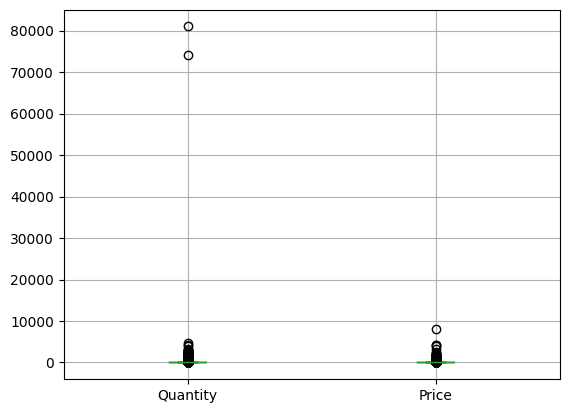

In [15]:
df[["Quantity", "Price"]].boxplot();

In [16]:
display(df[df["Quantity"] > 70000])

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346,United Kingdom
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446,United Kingdom


In [17]:
# 3. Tính tiền của từng dòng sản phẩm
df["TotalPrice"] = df["Quantity"] * df["Price"]

In [18]:
df.head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850,United Kingdom,15.30
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850,United Kingdom,25.50
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850,United Kingdom,11.10
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850,United Kingdom,11.10
9,536368,22960,JAM MAKING SET WITH JARS,6,2010-12-01 08:34:00,4.25,13047,United Kingdom,25.50


In [19]:
# Ngày phân tích: sau ngày mua cuối cùng trong dữ liệu 1 ngày
snapshot_date = df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

In [20]:
display(df.groupby("Customer ID").get_group(17850))

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
...,...,...,...,...,...,...,...,...,...
4540,536790,22752,SET 7 BABUSHKA NESTING BOXES,4,2010-12-02 15:26:00,7.65,17850,United Kingdom,30.60
4541,536790,22803,IVORY EMBROIDERED QUILT,3,2010-12-02 15:26:00,35.75,17850,United Kingdom,107.25
4542,536790,21730,GLASS STAR FROSTED T-LIGHT HOLDER,12,2010-12-02 15:26:00,4.25,17850,United Kingdom,51.00
4543,536791,22632,HAND WARMER RED POLKA DOT,12,2010-12-02 15:27:00,1.85,17850,United Kingdom,22.20


In [21]:
# 4. Tính RFM theo từng khách hàng
rfm = df.groupby("Customer ID").agg(
    Recency=("InvoiceDate",
             lambda dates: (snapshot_date - dates.max().normalize()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("TotalPrice", "sum")
).reset_index()

rfm["Monetary"] = rfm["Monetary"].round(2)

print("Ngày phân tích:", snapshot_date.date())
print(rfm.head(10))

Ngày phân tích: 2011-12-10
   Customer ID  Recency  Frequency  Monetary
0        12346      326          1  77183.60
1        12347        3          7   4310.00
2        12348       76          4   1797.24
3        12349       19          1   1757.55
4        12350      311          1    334.40
5        12352       37          8   2506.04
6        12353      205          1     89.00
7        12354      233          1   1079.40
8        12355      215          1    459.40
9        12356       23          3   2811.43


In [22]:
rfm.describe()

,Customer ID,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000,4338.000000
mean,15300.408022,93.059474,4.272015,2054.270609
std,1721.808492,100.012264,7.697998,8989.229895
min,12346.000000,1.000000,1.000000,3.750000
25%,13813.250000,18.000000,1.000000,307.415000
50%,15299.500000,51.000000,2.000000,674.485000
75%,16778.750000,142.750000,5.000000,1661.740000
max,18287.000000,374.000000,209.000000,280206.020000


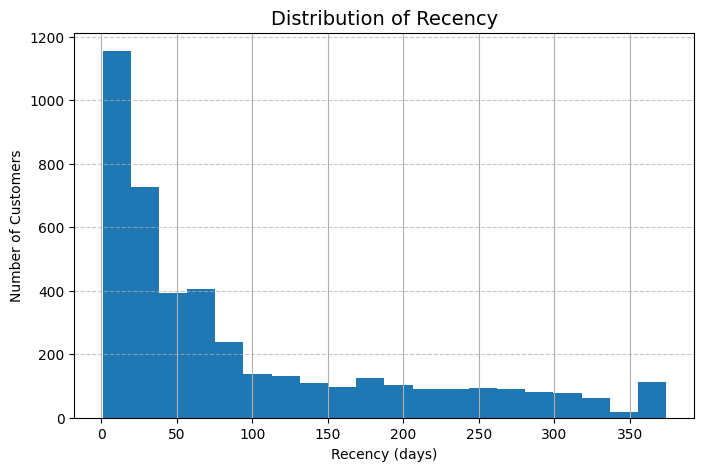

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

rfm["Recency"].hist(bins=20)

plt.title("Distribution of Recency", fontsize=14)
plt.xlabel("Recency (days)")
plt.ylabel("Number of Customers")
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.show()

In [24]:
print("Số hàng dữ liệu trong rfm:", len(rfm))

Số hàng dữ liệu trong rfm: 4338


In [25]:
# Tính các ngưỡng riêng cho từng cột
quantiles = rfm[["Recency", "Frequency", "Monetary"]].quantile(
    [0.2, 0.4, 0.6, 0.8]
)

# Recency: số ngày càng thấp, điểm càng cao
def RScore(x, thresholds):
    if x <= thresholds[0.2]:
        return 5
    elif x <= thresholds[0.4]:
        return 4
    elif x <= thresholds[0.6]:
        return 3
    elif x <= thresholds[0.8]:
        return 2
    else:
        return 1

# Frequency và Monetary: giá trị càng cao, điểm càng cao
def FMScore(x, thresholds):
    if x <= thresholds[0.2]:
        return 1
    elif x <= thresholds[0.4]:
        return 2
    elif x <= thresholds[0.6]:
        return 3
    elif x <= thresholds[0.8]:
        return 4
    else:
        return 5

# Chấm điểm
rfm["R_Score"] = rfm["Recency"].apply(
    RScore, args=(quantiles["Recency"],)
)

rfm["F_Score"] = rfm["Frequency"].apply(
    FMScore, args=(quantiles["Frequency"],)
)

rfm["M_Score"] = rfm["Monetary"].apply(
    FMScore, args=(quantiles["Monetary"],)
)

# Ghép ba điểm thành mã RFM
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

print(rfm.head())

   Customer ID  Recency  Frequency  Monetary  R_Score  F_Score  M_Score  \
0        12346      326          1  77183.60        1        1        5   
1        12347        3          7   4310.00        5        5        5   
2        12348       76          4   1797.24        2        4        4   
3        12349       19          1   1757.55        4        1        4   
4        12350      311          1    334.40        1        1        2   

  RFM_Score  
0       115  
1       555  
2       244  
3       414  
4       112  


In [26]:
df_data = rfm[[
    "Customer ID",
    "Recency",
    "Frequency",
    "Monetary",
    "R_Score",
    "F_Score",
    "M_Score",
    "RFM_Score"
]].copy()

print(df_data.head())

   Customer ID  Recency  Frequency  Monetary  R_Score  F_Score  M_Score  \
0        12346      326          1  77183.60        1        1        5   
1        12347        3          7   4310.00        5        5        5   
2        12348       76          4   1797.24        2        4        4   
3        12349       19          1   1757.55        4        1        4   
4        12350      311          1    334.40        1        1        2   

  RFM_Score  
0       115  
1       555  
2       244  
3       414  
4       112  


In [27]:
display(df_data.head())

,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346,326,1,77183.60,1,1,5,115
1,12347,3,7,4310.00,5,5,5,555
2,12348,76,4,1797.24,2,4,4,244
3,12349,19,1,1757.55,4,1,4,414
4,12350,311,1,334.40,1,1,2,112


In [28]:
import numpy as np
import pandas as pd

# 1. Tính điểm theo các mốc phân vị 20%, 40%, 60%, 80%.
# Các giá trị bằng nhau nhận cùng điểm.

# 2. Quy tắc chia nhóm theo bảng trong ảnh.
segment_rules = {
    "Champions":
        "555 554 544 545 454 455 445",

    "Loyal Customers":
        "543 444 435 355 354 345 344 335",

    "Potential Loyalist":
        "553 551 552 541 542 533 532 531 452 451 442 441 "
        "431 453 433 432 423 353 352 351 342 341 333 323",

    "Recent Customers":
        "512 511 422 421 412 411 311",

    "Promising":
        "525 524 523 522 521 515 514 513 425 424 413 414 "
        "415 315 314 313",

    "Customers Needing Attention":
        "535 534 443 434 343 334 325 324",

    "About To Sleep":
        "331 321 312 221 213",

    "At Risk":
        "255 254 245 244 253 252 243 242 235 234 225 224 "
        "153 152 145 143 142 135 134 133 125 124",

    "Can't Lose Them":
        "155 154 144 214 215 115 114 113",

    "Hibernating":
        "332 322 231 241 251 233 232 223 222 132 123 122 212 211",

    "Lost":
        "111 112 121 131 141 151",
}

label_map = {
    score: segment
    for segment, scores in segment_rules.items()
    for score in scores.split()
}

df_data["Segment"] = df_data["RFM_Score"].map(label_map).fillna("Unclassified")

# 3. Hiển thị kết quả.
display(df_data[
    ["Customer ID", "Recency",	"Frequency", 	"Monetary", "RFM_Score", "Segment"]
].head(10))

summary = (
    df_data["Segment"]
    .value_counts()
    .rename_axis("Nhóm khách hàng")
    .reset_index(name="Số khách hàng")
)

display(summary)
print("Số nhóm thực tế xuất hiện:", df_data["Segment"].nunique())

,Customer ID,Recency,Frequency,Monetary,RFM_Score,Segment
0,12346,326,1,77183.60,115,Can't Lose Them
1,12347,3,7,4310.00,555,Champions
2,12348,76,4,1797.24,244,At Risk
3,12349,19,1,1757.55,414,Promising
4,12350,311,1,334.40,112,Lost
5,12352,37,8,2506.04,355,Loyal Customers
6,12353,205,1,89.00,111,Lost
7,12354,233,1,1079.40,114,Can't Lose Them
8,12355,215,1,459.40,112,Lost
9,12356,23,3,2811.43,435,Loyal Customers


,Nhóm khách hàng,Số khách hàng
0,Champions,798
1,Hibernating,668
2,Lost,567
3,Recent Customers,407
4,Loyal Customers,403
5,At Risk,348
6,Potential Loyalist,307
7,Customers Needing Attention,254
8,Promising,243
9,About To Sleep,220


Số nhóm thực tế xuất hiện: 11


In [29]:
df_data.to_csv("rfm_data.csv", index=False, encoding="utf-8-sig")

In [30]:
from sklearn.preprocessing import StandardScaler

# Dữ liệu RFM gốc
X = df_data[["Recency",	"Frequency", "Monetary"]].copy()

# Giảm độ lệch và nén các giá trị lớn
X_log = np.log1p(X)

# Chuẩn hóa trước khi phân cụm
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

display(X.head())

,Recency,Frequency,Monetary
0,326,1,77183.60
1,3,7,4310.00
2,76,4,1797.24
3,19,1,1757.55
4,311,1,334.40


In [31]:
def silhouette(data: np.ndarray, labels: np.ndarray) -> float:
    from sklearn.metrics import silhouette_score
    return silhouette_score(data, labels)

def davies_bouldin(data: np.ndarray, labels: np.ndarray) -> float:
    from sklearn.metrics import davies_bouldin_score
    return davies_bouldin_score(data, labels)

def partition_coefficient(membership: np.ndarray) -> float:
    N, C = membership.shape
    _pc = np.sum(np.square(membership)) / N  # PC fuzzy
    _1dc = 1/C
    return (_pc - _1dc) / (1 - _1dc)

def extract_labels(membership: np.ndarray) -> np.ndarray:
    return np.argmax(membership, axis=1)

def Xie_Benie(data: np.ndarray, centroids: np.ndarray,
              membership: np.ndarray, m: float = 2) -> float:
    # XB = sum(u_ij ** m * ||x_i - v_j||^2) / (N * min ||v_j - v_k||^2).
    # Reference: https://www.mdpi.com/2078-2489/11/9/446
    if len(centroids) < 2:
        return np.nan
    squared_distances = cdist(data, centroids, metric="sqeuclidean")
    center_distances = cdist(centroids, centroids, metric="sqeuclidean")
    # Only exclude the diagonal: distinct coincident centers mean XB = inf.
    np.fill_diagonal(center_distances, np.inf)
    min_separation = np.min(center_distances)
    if min_separation <= 0:
        return np.inf
    numerator = np.sum((membership ** m) * squared_distances)
    return float(numerator / (len(data) * min_separation))

def accuracy_score(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    from sklearn.metrics import accuracy_score
    return accuracy_score(y_true, y_pred)

def f1_score(y_true: np.ndarray, y_pred: np.ndarray, average: str = 'weighted') -> float:  # binary|weighted
    from sklearn.metrics import f1_score
    return f1_score(y_true, y_pred, average=average)

def print_clustering_metrics(name, data, centroids, membership, y_true,
                             m=2, align_labels=False):
    """Print six validity scores; optionally match cluster IDs to true labels."""
    from scipy.optimize import linear_sum_assignment

    labels = extract_labels(membership)
    y_true = np.asarray(y_true)
    y_pred = labels.copy()

    if align_labels:
        # FCM cluster IDs are arbitrary: match them before Accuracy and F1.
        classes, true_ids = np.unique(y_true, return_inverse=True)
        contingency = np.zeros((len(classes), membership.shape[1]), dtype=int)
        np.add.at(contingency, (true_ids, labels), 1)
        class_ids, cluster_ids = linear_sum_assignment(-contingency)
        mapping = dict(zip(cluster_ids, classes[class_ids]))
        for cluster_id in range(membership.shape[1]):
            if cluster_id not in mapping:
                mapping[cluster_id] = classes[contingency[:, cluster_id].argmax()]
        y_pred = np.array([mapping[label] for label in labels])

    valid_partition = 2 <= len(np.unique(labels)) < len(data)
    scores = {
        "Silhouette": silhouette(data, labels) if valid_partition else np.nan,
        "Davies-Bouldin": davies_bouldin(data, labels) if valid_partition else np.nan,
        "Partition Coefficient (normalized)": (
            partition_coefficient(membership) if membership.shape[1] > 1 else np.nan
        ),
        "Xie-Beni": Xie_Benie(data, centroids, membership, m=m),
        "Accuracy": accuracy_score(y_true, y_pred),
        "F1 (weighted)": f1_score(y_true, y_pred, average="weighted"),
    }
    print(f"\n=== {name} ===")
    for metric, value in scores.items():
        print(f"{metric:<36}: {value:.6f}")
    if not valid_partition:
        print("Silhouette / Davies-Bouldin: undefined for this number of clusters.")
    return scores


In [32]:
class FCM:

    # hàm khởi tạo
    def __init__(self, c: int, m: int = 2, max_iters: int = 1000, eps: float = 1e-5):
        self.c=c
        self.m=m
        self.max_iters=max_iters
        self.eps=eps
        self.U=None
        self.V=None
        self.process_time=0

    # khởi tạo ma trận thành viên ngẫu nhiên
    def initialize_U(self, data : np.ndarray)-> np.ndarray:
        n=data.shape[0] #lấy số lượng điểm dữ liệu
        np.random.seed(seed=42)
        U = np.random.rand(n, self.c)
        U = U/np.sum(U, axis=1, keepdims=True)
        return U

    #tính tâm cụm
    def calculate_V(self, data: np.ndarray) -> np.ndarray:
        um = self.U ** self.m
        return (um.T @ data) / division_by_zero(np.sum(um.T, axis=1, keepdims=True))

    #Cập nhật ma trận thành viên
    def update_membership_matrix(self, data: np.ndarray) -> np.ndarray:
        distance = cdist(data, self.V, metric='euclidean') ** (2 / (self.m - 1))
        D = [distance[:, j] for j in range(self.c)]
        numerator = 1 / np.array(D)
        denominator = np.sum(numerator, axis=0)
        U = numerator / division_by_zero(denominator)
        return np.squeeze(U).T

    def fit(self, data: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray, int]:
        import time
        self.U = self.initialize_U(data)
        start_time = time.time()

        for i in range(self.max_iters):
            U_old = self.U.copy()
            self.V = self.calculate_V(data)
            self.U = self.update_membership_matrix(data)
            if np.linalg.norm(self.U - U_old) < self.eps:
                break

        end_time = time.time()
        self.process_time = end_time - start_time
        return self   # Trả về số vòng lặp thực tế

    def predict(self, U):
        return np.argmax(U, axis=1)
def division_by_zero(data: np.ndarray | float) -> np.ndarray | float:
        if isinstance(data, np.ndarray):
            data[data == 0] = np.finfo(float).eps
            return data
        return np.finfo(float).eps if data == 0 else data


In [33]:
from sklearn.preprocessing import LabelEncoder

labelencoder = LabelEncoder()
Y = labelencoder.fit_transform(df_data["Segment"])

In [34]:
c = len(np.unique(Y))
print("Số nhãn:", c)

Số nhãn: 11


In [35]:
fcm = FCM(c, m = 1.5) 
fcm.fit(X_scaled)
labels_pred = fcm.predict(fcm.U) 
centers_scaled = fcm.V

fcm_metrics = print_clustering_metrics(
    "FCM", X_scaled, fcm.V, fcm.U, Y, m=fcm.m, align_labels=True
)



=== FCM ===
Silhouette                          : 0.269978
Davies-Bouldin                      : 1.065482
Partition Coefficient (normalized)  : 0.622167
Xie-Beni                            : 0.424841
Accuracy                            : 0.466113
F1 (weighted)                       : 0.469289


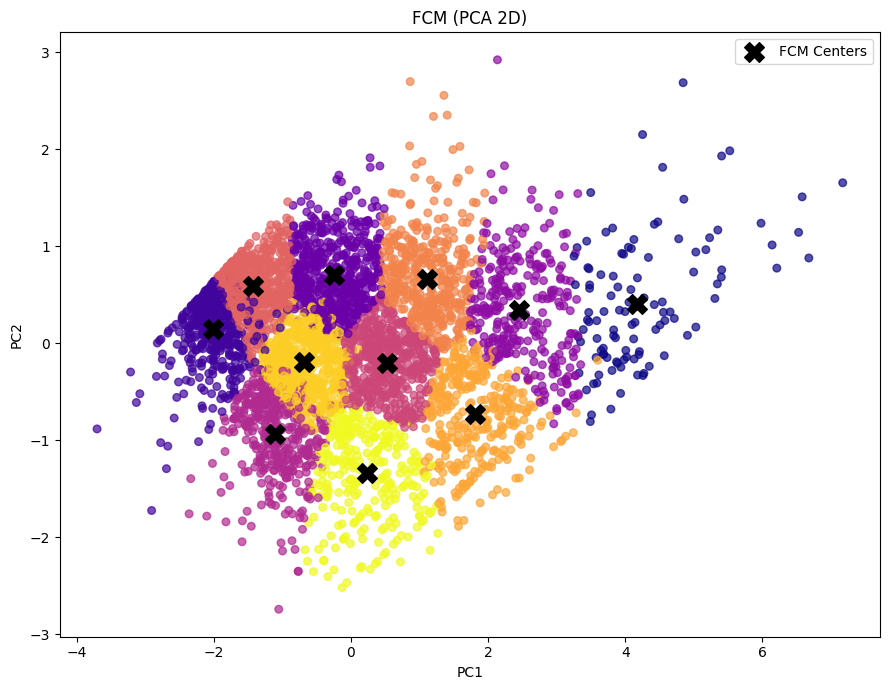

In [36]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Nhãn và tâm cụm của FCM đã huấn luyện trên X_scaled
labels_fcm = fcm.predict(fcm.U)

# PCA để vẽ 2D
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)
fcm_centers_2d = pca.transform(fcm.V)

fig, ax = plt.subplots(figsize=(9, 7))

ax.scatter(
    X_2d[:, 0], X_2d[:, 1],
    c=labels_fcm, cmap="plasma", s=30, alpha=0.7
)

ax.scatter(
    fcm_centers_2d[:, 0], fcm_centers_2d[:, 1],
    c="black", marker="X", s=200, label="FCM Centers"
)

ax.set_title("FCM (PCA 2D)")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend()

plt.tight_layout()
plt.show()

In [37]:
import numpy as np
from scipy.spatial.distance import cdist
import time


class SSFCM:
    def __init__(self, clusters, m=2, max_iter=1000, eps=1e-5, per=30):
        self.clusters = clusters
        self.m = m
        self.max_iter = max_iter
        self.eps = eps
        self.per = per
        self.U_bar = None
        self.process_time = 0


    # ================== Tạo ngẫu nhiên nhãn =========
    def mask_labels_balanced(y, percent=30):
        y = np.array(y)
        y_partial = np.full(len(y), -1)

        classes = np.unique(y)

        for c in classes:
            idx = np.where(y == c)[0]
            num_keep = int(len(idx) * percent / 100)

            keep_idx = np.random.choice(idx, num_keep, replace=False)
            y_partial[keep_idx] = c

        return y_partial
    # ================== FCM CORE ==================

    def initialize_random_membership_matrix(self, data):
        np.random.seed(42)
        n = data.shape[0]
        U = np.random.rand(n, self.clusters)
        U = U / np.sum(U, axis=1, keepdims=True)
        return U

    def calculate_centroid(self, data, U):
        Um = U ** self.m
        TS = np.dot(Um.T, data)
        MS = np.sum(Um.T, axis=1, keepdims=True)
        return TS / MS

    def update_membership_matrix(self, data, centroids):
        distance = cdist(data, centroids, metric='sqeuclidean')

        # tránh chia cho 0
        distance = np.fmax(distance, 1e-10)

        power = 1 / (self.m - 1)
        inv_dist = distance ** (-power)

        U = inv_dist / np.sum(inv_dist, axis=1, keepdims=True)
        return U

    # ================== SEMI-SUPERVISED ==================

    def init_U_bar(self, labels):
        self.U_bar = np.zeros((len(labels), self.clusters))
        for i in range(len(labels)):
            if labels[i] != -1 and labels[i] < self.clusters:
                self.U_bar[i][labels[i]] = 1
         # Đếm số lượng giá trị 1 ở từng cột
        count = np.sum(self.U_bar == 1, axis=0)
    
        # print("Number of labeled samples per cluster:")
        # for i, c in enumerate(count):
        #     print(f"Cluster {i}: {c}")
        return self.U_bar

    def calculate_centroid_ss(self, data, U):
        U_eff = np.abs(U - self.U_bar)
        # U_eff = U - self.U_bar
        return self.calculate_centroid(data, U_eff)

    def update_membership_matrix_ss(self, data, centroids):
        u = self.update_membership_matrix(data, centroids)
        matrix_1_Sum_U = 1 - np.sum(self.U_bar, axis=1, keepdims=True)
        return self.U_bar + matrix_1_Sum_U * u

    # ================== TRAIN ==================

    def fit(self, data, labels):
        self.U_bar = self.init_U_bar(labels)
        U = self.initialize_random_membership_matrix(data)

        starttime = time.time()

        for i in range(self.max_iter):
            centroids = self.calculate_centroid_ss(data, U)
            new_U = self.update_membership_matrix_ss(data, centroids)

            if np.linalg.norm(new_U - U) < self.eps:
                break

            U = new_U.copy()

        self.process_time = time.time() - starttime
        final_labels = np.argmax(U, axis=1) # là hàm def predict(self, U):

        return centroids, U, final_labels, i

    # ================== PREDICT ==================

    def predict(self, U):
        return np.argmax(U, axis=1)


In [38]:
def mask_labels_balanced(y, percent=30):
    y = np.array(y)
    label = np.full(len(y), -1)

    classes = np.unique(y)

    for c in classes:
        # print("class:", c)
        idx = np.where(y == c)[0]
        if int(len(idx) * percent / 100) <= 1: 
            num_keep = 1
            # print(num_keep)
        else:
            num_keep = int(len(idx) * percent / 100)
            # print(num_keep)
        np.random.seed(42)
        keep_idx = np.random.choice(idx, num_keep, replace=False)
        label[keep_idx] = c

    return label

# def mask_labels_balanced(y, percent=30):
#         y = np.array(y)
#         y_partial = np.full(len(y), -1)

#         classes = np.unique(y)

#         for c in classes:
#             idx = np.where(y == c)[0]
#             num_keep = int(len(idx) * percent / 100)

#             keep_idx = np.random.choice(idx, num_keep, replace=False)
#             y_partial[keep_idx] = c

#         return y_partial

In [39]:
L = mask_labels_balanced(Y, percent=20.0)
ssfcm = SSFCM(clusters = c, m = 2)
centroids,U,labels,i = ssfcm.fit(X_scaled,L)
label_pred = ssfcm.predict(U)

ssfcm_metrics = print_clustering_metrics(
    "SSFCM", X_scaled, centroids, U, Y, m=ssfcm.m
)



=== SSFCM ===
Silhouette                          : 0.152745
Davies-Bouldin                      : 1.509056
Partition Coefficient (normalized)  : 0.420322
Xie-Beni                            : 0.798529
Accuracy                            : 0.485016
F1 (weighted)                       : 0.506883


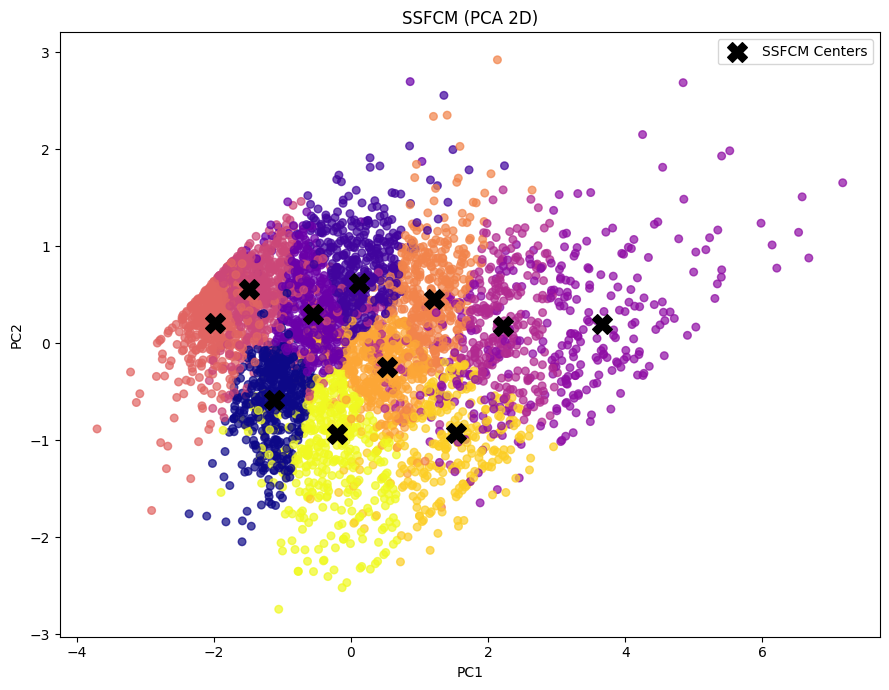

In [40]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# PCA để vẽ 2D
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)
centers_2d = pca.transform(centroids)

fig, ax = plt.subplots(figsize=(9, 7))

ax.scatter(
    X_2d[:, 0], X_2d[:, 1],
    c=label_pred, cmap="plasma", s=30, alpha=0.7
)

ax.scatter(
    centers_2d[:, 0], centers_2d[:, 1],
    c="black", marker="X", s=200, label="SSFCM Centers"
)

ax.set_title("SSFCM (PCA 2D)")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend()

plt.tight_layout()
plt.show()

In [41]:
from sklearn.cluster import KMeans

def hard_to_membership(labels, n_clusters):
    """Nhãn cứng -> ma trận thành viên one-hot (N, c)."""
    labels = np.asarray(labels)
    U = np.zeros((len(labels), n_clusters))
    U[np.arange(len(labels)), labels] = 1.0
    return U

km = KMeans(n_clusters=c, random_state=42).fit(X_scaled)
U_km = hard_to_membership(km.labels_, c)

km_metrics = print_clustering_metrics(
    "KMeans", X_scaled, km.cluster_centers_, U_km, Y, m=2, align_labels=True
)

C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Program Files\Python313\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Program Files\Python313\Lib\subprocess.py", line 1036, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
 


=== KMeans ===
Silhouette                          : 0.274551
Davies-Bouldin                      : 1.026913
Partition Coefficient (normalized)  : 1.000000
Xie-Beni                            : 0.500976
Accuracy                            : 0.456201
F1 (weighted)                       : 0.462335


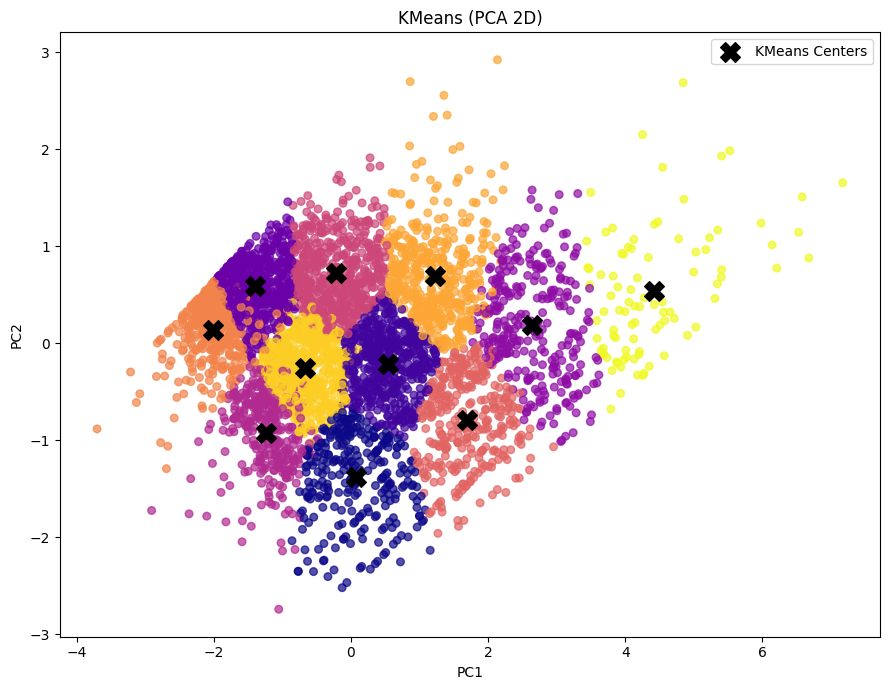

In [42]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# PCA để vẽ 2D
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)
km_centers_2d = pca.transform(km.cluster_centers_)

fig, ax = plt.subplots(figsize=(9, 7))

ax.scatter(
    X_2d[:, 0], X_2d[:, 1],
    c=km.labels_, cmap="plasma", s=30, alpha=0.7
)

ax.scatter(
    km_centers_2d[:, 0], km_centers_2d[:, 1],
    c="black", marker="X", s=200, label="KMeans Centers"
)

ax.set_title("KMeans (PCA 2D)")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend()

plt.tight_layout()
plt.show()

In [43]:
import pandas as pd

results = pd.DataFrame({
    "FCM": fcm_metrics,
    "SSFCM": ssfcm_metrics,
    "KMeans": km_metrics,
}).round(4)
display(results)

,FCM,SSFCM,KMeans
Silhouette,0.2700,0.1527,0.2746
Davies-Bouldin,1.0655,1.5091,1.0269
Partition Coefficient (normalized),0.6222,0.4203,1.0000
Xie-Beni,0.4248,0.7985,0.5010
Accuracy,0.4661,0.4850,0.4562
F1 (weighted),0.4693,0.5069,0.4623
